# 16 · Audit public ratings datasets for whole-series recommendations

**Question:** Which public ratings source best supports Afterglow: movies and whole TV series, individual user scores, shared movie/TV users, stable title identities, and an honest evaluation protocol?

Compare **FilmAffinity Reviews + Information**, **MyAnimeList 2020**, and **Douban MovieData-10M**. This notebook audits actual retrievable records wherever possible. Published totals, schemas, samples and access failures are labeled separately.

**Whole series means the series as a title—not a season or episode.** Do not silently turn a season score into a score for the parent series. Anime `Type=TV` alone does not prove whole multi-season granularity.

This audit does not train a model, read benchmark test feedback, change existing experiments, or modify the app. It uses no paid API. All existing movie-model results remain separate from this new source audit.


In [1]:
from pathlib import Path
import os
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "scripts").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "scripts/ratings_dataset_audit.py").is_file(), "Run from the project or notebooks folder."
sys.path.insert(0, str(ROOT))
(ROOT / "data/.matplotlib").mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "data/.matplotlib"))

import json
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from scripts.prepare_ratings_dataset_audit import prepare_sources, CACHE_RELATIVE, sha256_file
from scripts.ratings_dataset_audit import run_audit
pd.set_option("display.max_columns", 18)
pd.set_option("display.max_colwidth", 85)


## Source scope and acquisition

| Dataset | Public source | What is audited |
|---|---|---|
| FilmAffinity | [Curator release](https://huggingface.co/datasets/naim-prog/filmaffinity-reviews-info) | Both complete published Parquet files, including individual review-associated ratings |
| MyAnimeList 2020 | [Curator repository](https://github.com/Hernan4444/MyAnimeList-Database) | Anime metadata and the small GitHub rating samples; full population totals remain **curator claims**, not measured counts |
| Douban MovieData-10M | [Curator documentation](https://github.com/csuldw/AntSpider/blob/master/docs/README.md) | Published schemas/conditions and public sample accessibility; no gated-archive bypass |

The first preparation downloads about 450 MB of FilmAffinity data plus small source files. Store inputs in a dedicated cache, pin immutable repository revisions, and verify byte counts and SHA-256 hashes. Reruns can be entirely offline.

The full MAL ratings are published through external links and are not downloaded here. The repository's ordered small sample cannot establish population coverage. Douban's full archive requires a curator-supplied password; this audit records that restriction without requesting accounts, following social accounts or sending messages.

Install the optional Parquet reader into the existing project environment using `requirements-audit.txt`. No separate virtual environment is needed.


In [2]:
FETCH_INPUTS = False  # Set True only when preparing missing sources or retrying public access.
if FETCH_INPUTS:
    source_manifest = prepare_sources(ROOT)
else:
    source_manifest_path = ROOT / CACHE_RELATIVE / "manifest.json"
    assert source_manifest_path.is_file(), (
        "Run .venv/Scripts/python.exe scripts/prepare_ratings_dataset_audit.py first, "
        "or set FETCH_INPUTS=True."
    )
    source_manifest = json.loads(source_manifest_path.read_text(encoding="utf-8"))
access = pd.DataFrame(source_manifest["assets"])
display(access[["dataset", "kind", "status", "scope", "bytes", "revision", "error"]])
print("Successful inputs:", int(access["status"].eq("ok").sum()))
print("All acquisition failures/restrictions are retained in the report.")


Successful inputs: 19
All acquisition failures/restrictions are retained in the report.


,dataset,kind,status,scope,bytes,revision,error
0,filmaffinity,repository_metadata,ok,repository snapshot and file identities,3925,NaN,NaN
1,filmaffinity,documentation,ok,dataset card,3375,05d8f46e937af0fd473f5d200b8a83575c93643d,NaN
2,filmaffinity,information,ok,complete published file,12997513,05d8f46e937af0fd473f5d200b8a83575c93643d,NaN
3,filmaffinity,ratings,ok,complete published file,437059698,05d8f46e937af0fd473f5d200b8a83575c93643d,NaN
4,mal2020,repository_metadata,ok,pin curator repository revision,6637,NaN,NaN
5,mal2020,repository_tree,ok,verify source paths and file identities,3292,9a1d7f56482accbde99e24cd7cfcad65e2d24b1f,NaN
6,mal2020,documentation,ok,"curator README; population counts are claims, not measured samples",2548,9a1d7f56482accbde99e24cd7cfcad65e2d24b1f,NaN
7,mal2020,documentation,ok,curator schema and sample limitations,5849,9a1d7f56482accbde99e24cd7cfcad65e2d24b1f,NaN
8,mal2020,information,ok,exact curator GitHub metadata file; inspect actual row count,5662362,9a1d7f56482accbde99e24cd7cfcad65e2d24b1f,NaN
9,mal2020,ratings_with_status,ok,"curator's 500-line sample, not 109 million interactions",6949,9a1d7f56482accbde99e24cd7cfcad65e2d24b1f,NaN


## Prespecified audit rules

1. **Explicit ratings only.** Validate user and title IDs and numeric scores. Unrated/unknown entries are not dislikes.
2. **Conservative rating units.** Use explicit format labels and synopsis headers. A description saying “26 episodes” describes a series; it does not make the entry an episode. Explicit season/episode evidence overrides broad series labels. Uncertain entries remain uncertain.
3. **Separate evidence from certainty.** FilmAffinity classification uses metadata rules. “High/medium confidence” means stronger/weaker rule evidence, not calibrated correctness probabilities or certified IMDb identities. Export examples for human review.
4. **Movie inference is disclosed.** FilmAffinity commonly leaves ordinary movie format tags blank. Untagged feature-length entries are treated as **movie candidates**, with this inference reported separately. Shared movie/TV-user counts therefore depend on both unit rules.
5. **No duplicate inflation.** Keep the latest valid review-dated user/title score. Conflicting scores at the same latest timestamp, or conflicting all-undated records, remove the pair rather than arbitrarily choosing one.
6. **Dates retain their meaning.** A FilmAffinity review publication date is not proof of when the rating was first assigned or last changed. MAL event dates are not invented from anime air dates. Dates support a protocol discussion, not an automatic claim of chronological evaluation readiness.
7. **Keep source users separate.** User `0` in MAL is not a MovieLens or FilmAffinity user. Cross-source shared preferences require real identity evidence and consent, not matching integers.
8. **No size-only winner.** Prefer actual usable whole-series/user coverage, shared movie/TV histories, title linkage, timestamps, access and documented usage conditions. Do not rank a 499-row sample against a full dataset as if both were complete populations.

The recommendation is a **prototype-data choice**, not a claim that a trained TV model already outperforms another model or an LLM.


In [3]:
result = run_audit(ROOT)
assert result["report"]["models_trained"] is False
assert result["report"]["test_feedback_read"] is False
assert result["report"]["app_changed"] is False
print("Saved audited results:", result["output"])
columns = ["dataset", "scope", "access", "catalog_rows", "raw_rating_rows",
           "n_ratings", "n_users", "n_whole_series_ratings",
           "n_whole_series_users", "n_users_movies_and_series"]
display(result["summary"].reindex(columns=columns).style.format(na_rep="Not measured / not established"))


Auditing FilmAffinity's actual metadata and individual rating rows...
Auditing MyAnimeList metadata and the published small rating sample...
Auditing Douban access and documented schema...
Saved audited results: C:\Users\clark\OneDrive\Documents\Projects\movie-recommendation-system\data\processed\notebook16_dataset_audit


,dataset,scope,access,catalog_rows,raw_rating_rows,n_ratings,n_users,n_whole_series_ratings,n_whole_series_users,n_users_movies_and_series
0,FilmAffinity,full published snapshot,retrieved and hash-verified,24369.000000,419827.000000,419827.000000,55148.000000,35489.000000,13094.000000,8350.000000
1,MyAnimeList 2020,full curator metadata plus first published rating sample; NOT full 57M ratings,metadata and sample retrieved,17562.000000,499.000000,499.000000,4.000000,Not measured / not established,Not measured / not established,Not measured / not established
2,Douban MovieData-10M,documentation and access audit; whole-series rating coverage unverified,public sample unavailable; full archive password-gated,Not measured / not established,Not measured / not established,Not measured / not established,Not measured / not established,Not measured / not established,Not measured / not established,Not measured / not established


In [4]:
fa = result["report"]["datasets"]["filmaffinity"]
if fa:
    display(Markdown("### FilmAffinity: measured individual-rating coverage"))
    display(pd.DataFrame([fa["quality"]]))
    display(pd.DataFrame([fa["metrics"]]).T.rename(columns={0: "measured value"}))
    display(result["exports"]["filmaffinity_unit_counts.csv"])
    title_coverage = result["exports"]["filmaffinity_title_coverage.csv"]
    series = title_coverage.loc[title_coverage["unit"] == "whole_series"].sort_values("n_ratings", ascending=False)
    display(series[["item_id", "original_title", "year", "confidence", "n_ratings", "n_users", "dated_ratings"]].head(20).reset_index(drop=True))
    display(Markdown(
        f"Measured **{fa['metrics']['n_whole_series_ratings']:,} ratings** joined to "
        f"**{fa['metrics']['n_whole_series_items']:,} whole-series candidates**, "
        f"from **{fa['metrics']['n_whole_series_users']:,} users**. "
        f"**{fa['metrics']['n_users_movies_and_series']:,} users** have both movie-candidate and whole-series-candidate ratings. "
        "These are metadata-classification results; inspect unit examples before treating every candidate as a verified whole series."
    ))
    print("Date semantics:", fa["rating_date_semantics"])
    print("Selection bias:", fa["sample_bias"])
    print("Movie labels:", fa["movie_unit_semantics"])


Date semantics: Review publication dates are proxies, not proof of original/last-updated rating time.
Selection bias: Only published reviews with a score, not every FilmAffinity rating; reviewer selection and scraping coverage can bias preferences.
Movie labels: Ordinary untagged, feature-length entries are inferred movies; strict explicit-movie overlap is reported separately.


### FilmAffinity: measured individual-rating coverage

,raw_rows,missing_identity_rows,invalid_rating_rows,invalid_date_rows,duplicate_pairs,exact_duplicate_rows,ambiguous_latest_pairs,rows_cleaned,clean_rows_with_date
0,419827,0,0,0,0,0,0,419827,419827


,measured value
n_ratings,419827
n_users,55148
n_items,15549
n_whole_series_ratings,35489
n_whole_series_users,13094
n_whole_series_items,2502
n_movie_ratings,356550
n_users_movies_and_series,8350
n_users_whole_series_ge_5,1281
n_users_whole_series_ge_10,514


,unit,confidence,ratings,users,titles,dated_ratings
0,episode,high,1572,605,283,1572
1,movie,medium,356550,48461,10472,356550
2,season,high,204,163,15,204
3,uncertain,low,26012,9273,2277,26012
4,whole_series,high,20144,9542,850,20144
5,whole_series,medium,15345,6205,1652,15345


,item_id,original_title,year,confidence,n_ratings,n_users,dated_ratings
0,film489970,Breaking Bad,2008,high,497,497,497
1,film370639,Lostaka,2004,high,467,467,467
2,film399474,The Wireaka,2002,high,390,390,390
3,film372160,The Simpsons,1989,high,349,349,349
4,film561333,The Walking Dead,2010,high,274,274,274
5,film622579,Lord of the Rings: The Rings of Power,2022,high,273,273,273
6,film402150,The Sopranos,1999,high,240,240,240
7,film585998,Six Feet Under,2001,high,234,234,234
8,film745751,Stranger Things,2016,medium,215,215,215
9,film482444,Dexter,2006,high,208,208,208


Measured **35,489 ratings** joined to **2,502 whole-series candidates**, from **13,094 users**. **8,350 users** have both movie-candidate and whole-series-candidate ratings. These are metadata-classification results; inspect unit examples before treating every candidate as a verified whole series.

In [5]:
if fa:
    examples = result["exports"]["filmaffinity_classification_examples.csv"]
    display(Markdown("### Known whole-series, season and episode examples"))
    known = examples.loc[examples["item_id"].isin(
        ["film103430", "film103372", "film103496", "film100216", "film100483", "film100160"])]
    display(known[["item_id", "original_title", "unit", "confidence", "n_ratings", "evidence", "synopsis"]])
    display(Markdown(
        "Dark, Ugly Betty and Les Revenants are useful whole-series checks. "
        "American Horror Story: Roanoke is a season-specific counterexample; Dr. Stone: Ryusui is an episode/special entry. "
        "The exported classification examples also include a fixed-seed sample of every unit for manual review."
    ))
    display(examples[["item_id", "original_title", "unit", "confidence", "n_ratings", "synopsis"]])


### Known whole-series, season and episode examples

,item_id,original_title,unit,confidence,n_ratings,evidence,synopsis
3,film100160,Dr. Stone: Ryusui,episode,high,1,Explicit episode format label,"Especial de 1 hora para la televisión de ""Dr. Stone"", centrado en el personaje de..."
5,film100216,Helstrom,whole_series,medium,1,"Series/mini-series label or synopsis header, without explicit season/episode marker",Serie de TV (2020). 10 episodios. Daimon y Ana Helstrom son hijo e hija de un mis...
11,film100483,American Horror Story: My Roanoke Nightmare,season,high,21,Synopsis asserts a season-specific unit at its opening,"Miniserie de TV (2016). Sexta temporada. 10 episodios. Cuando una pareja, es asal..."
86,film103372,Ugly Betty,whole_series,high,14,Series label/header plus full run or plural season count; still subject to manual...,Serie de TV (2006-2010). 4 temporadas. 85 episodios. Betty Suarez (America Ferrer...
87,film103430,Dark,whole_series,high,184,Series label/header plus full run or plural season count; still subject to manual...,Serie de TV (2017-2020). 3 temporadas. 26 episodios. Tras la desaparición de un j...
89,film103496,Les Revenants (The Returned)aka,whole_series,high,45,Series label/header plus full run or plural season count; still subject to manual...,"Serie de TV (2012-2015). 2 Temporadas. 16 Episodios. En Annecy, un idílico pueblo..."


Dark, Ugly Betty and Les Revenants are useful whole-series checks. American Horror Story: Roanoke is a season-specific counterexample; Dr. Stone: Ryusui is an episode/special entry. The exported classification examples also include a fixed-seed sample of every unit for manual review.

,item_id,original_title,unit,confidence,n_ratings,synopsis
3,film100160,Dr. Stone: Ryusui,episode,high,1,"Especial de 1 hora para la televisión de ""Dr. Stone"", centrado en el personaje de..."
5,film100216,Helstrom,whole_series,medium,1,Serie de TV (2020). 10 episodios. Daimon y Ana Helstrom son hijo e hija de un mis...
11,film100483,American Horror Story: My Roanoke Nightmare,season,high,21,"Miniserie de TV (2016). Sexta temporada. 10 episodios. Cuando una pareja, es asal..."
86,film103372,Ugly Betty,whole_series,high,14,Serie de TV (2006-2010). 4 temporadas. 85 episodios. Betty Suarez (America Ferrer...
87,film103430,Dark,whole_series,high,184,Serie de TV (2017-2020). 3 temporadas. 26 episodios. Tras la desaparición de un j...
89,film103496,Les Revenants (The Returned)aka,whole_series,high,45,"Serie de TV (2012-2015). 2 Temporadas. 16 Episodios. En Annecy, un idílico pueblo..."
15176,film664680,Your Friends & Neighbors,whole_series,medium,13,"Serie de TV (2025-). 1 temporada. 9 episodios. Tras ser despedido con deshonor, u..."
9033,film436321,Kyōryū Shōjo Gauko,whole_series,medium,0,Serie de TV (2019). 20 episodios. Naoko Watanabe es una niña aparentemente normal...
14205,film628006,Spriggan,whole_series,medium,2,Serie de TV (2022). 6 episodios. Yū Ominae es un estudiante de instituto que es u...
14137,film625390,The Wonder Years,whole_series,high,7,Serie de TV (2021-2023). 2 temporadas. 32 episodios. Historia de la familia Willi...


In [6]:
if fa:
    links = result["exports"]["filmaffinity_local_title_links.csv"]
    display(links.groupby(["unit", "match_status"]).size().rename("titles").reset_index())
    display(Markdown(
        "These are **proposed exact normalized title/year matches to our limited local catalog**. "
        "They are not an official IMDb/TMDB crosswalk, and unmatched does not mean a title is absent from those services. "
        "No fuzzy or popularity-based identity guesses are used."
    ))
    users = result["exports"]["filmaffinity_user_coverage.csv"]
    readiness = pd.DataFrame([
        {"measure": "Users with at least 5 series-candidate ratings", "count": int(users["series_ratings"].ge(5).sum())},
        {"measure": "Users with at least 10 series-candidate ratings", "count": int(users["series_ratings"].ge(10).sum())},
        {"measure": "Users with at least 5 movie and 5 series-candidate ratings",
         "count": int((users["movie_ratings"].ge(5) & users["series_ratings"].ge(5)).sum())},
    ])
    display(readiness)
    print("Observed review-date range:", fa["date_range"])
    display(Markdown(
        "History depth makes a prototype more feasible, but a review-date split must be labeled as a proxy. "
        "The published score may have been updated after the review was posted. "
        "Do not silently present this as a verified original-rating chronological test."
    ))


Observed review-date range: {'min': '2005-05-07 00:00:00+00:00', 'max': '2025-08-20 00:00:00+00:00'}


,unit,match_status,titles
0,episode,unmatched,656
1,movie,proposed_unique,2195
2,movie,unmatched,12543
3,season,unmatched,21
4,uncertain,unmatched,4693
5,whole_series,proposed_unique,103
6,whole_series,unmatched,4158


These are **proposed exact normalized title/year matches to our limited local catalog**. They are not an official IMDb/TMDB crosswalk, and unmatched does not mean a title is absent from those services. No fuzzy or popularity-based identity guesses are used.

,measure,count
0,Users with at least 5 series-candidate ratings,1281
1,Users with at least 10 series-candidate ratings,514
2,Users with at least 5 movie and 5 series-candidate ratings,1063


History depth makes a prototype more feasible, but a review-date split must be labeled as a proxy. The published score may have been updated after the review was posted. Do not silently present this as a verified original-rating chronological test.

In [7]:
mal = result["report"]["datasets"]["mal2020"]
douban = result["report"]["datasets"]["douban10m"]
display(Markdown("### MyAnimeList: measured sample versus published totals"))
if mal:
    display(pd.DataFrame([mal["metrics"]]))
    display(pd.DataFrame([mal["published_not_measured"]]))
    display(result["exports"]["mal2020_season_entry_examples.csv"].head(12))
    for limitation in mal["limitations"]:
        print("MAL:", limitation)

display(Markdown("### Douban: documented schema and actual access status"))
display(pd.DataFrame(douban["access"])[["kind", "status", "error"]])
display(pd.DataFrame([douban["published_not_measured"]]))
for limitation in douban["limitations"]:
    print("Douban:", limitation)


MAL: The 500-row rating file is ordered/curator-selected, not a representative random sample.
MAL: TV entry IDs may identify seasons/sequels; do not relabel them as whole-series ratings.
MAL: No event timestamps: do not substitute anime air dates, season labels or user registration dates.
MAL: Anime-only domain and unverified license limit direct use for the requested broad movie/TV app.
Douban: No measured TV rating count is available from documentation alone.
Douban: Crawler hardcodes type='movie'; this field cannot distinguish movies from series.
Douban: A gated full archive was not accessed or bypassed.


### MyAnimeList: measured sample versus published totals

,observed_sample_ratings,observed_sample_users,observed_sample_items,sample_ratings_on_tv_entries,sample_ratings_on_movie_entries,catalog_tv_entries,catalog_explicit_season_name_markers,catalog_movies,orphan_sample_ratings
0,499,4,445,419,48,4996,423,3041,0


,complete_scored_ratings,users,anime_items,source
0,57000000,310059,16872,pinned data/readme.md


,item_id,title,unit,source_type,tv_entry,season_name_marker,evidence
60,81,Mobile Suit Gundam: The 08th MS Team,uncertain,OVA,False,True,Source anime format
62,83,Mobile Suit Gundam: The 08th MS Team - Miller's Report,movie,Movie,False,True,Source anime format
217,241,Girls Bravo: First Season,uncertain,TV,True,True,Anime-entry rating unit; TV is not a verified whole multi-season series
267,291,D.C.S.S: Da Capo Second Season,uncertain,TV,True,True,Anime-entry rating unit; TV is not a verified whole multi-season series
338,362,Memories Off 2nd,uncertain,OVA,False,True,Source anime format
371,395,Gantz 2nd Stage,uncertain,TV,True,True,Anime-entry rating unit; TV is not a verified whole multi-season series
457,487,Girls Bravo: Second Season,uncertain,TV,True,True,Anime-entry rating unit; TV is not a verified whole multi-season series
507,540,Tenchi Muyou! Ryououki 2nd Season,uncertain,OVA,False,True,Source anime format
508,541,Tenchi Muyou! Ryououki 3rd Season,uncertain,OVA,False,True,Source anime format
728,801,Koukaku Kidoutai: Stand Alone Complex 2nd GIG,uncertain,TV,True,True,Anime-entry rating unit; TV is not a verified whole multi-season series


### Douban: documented schema and actual access status

,kind,status,error
0,repository_metadata,ok,NaN
1,repository_tree,ok,NaN
2,documentation,ok,NaN
3,documentation,ok,NaN
4,schema,ok,NaN
5,collection_code,ok,NaN
6,license,ok,NaN
7,sample_archive,unavailable,URLError: <urlopen error [Errno 11001] getaddrinfo failed>
8,full_archive,restricted,"Curator documents a password obtained through WeChat. No login, follow, message, ..."


,ratings,users,rated_items
0,4169420,600384,68471


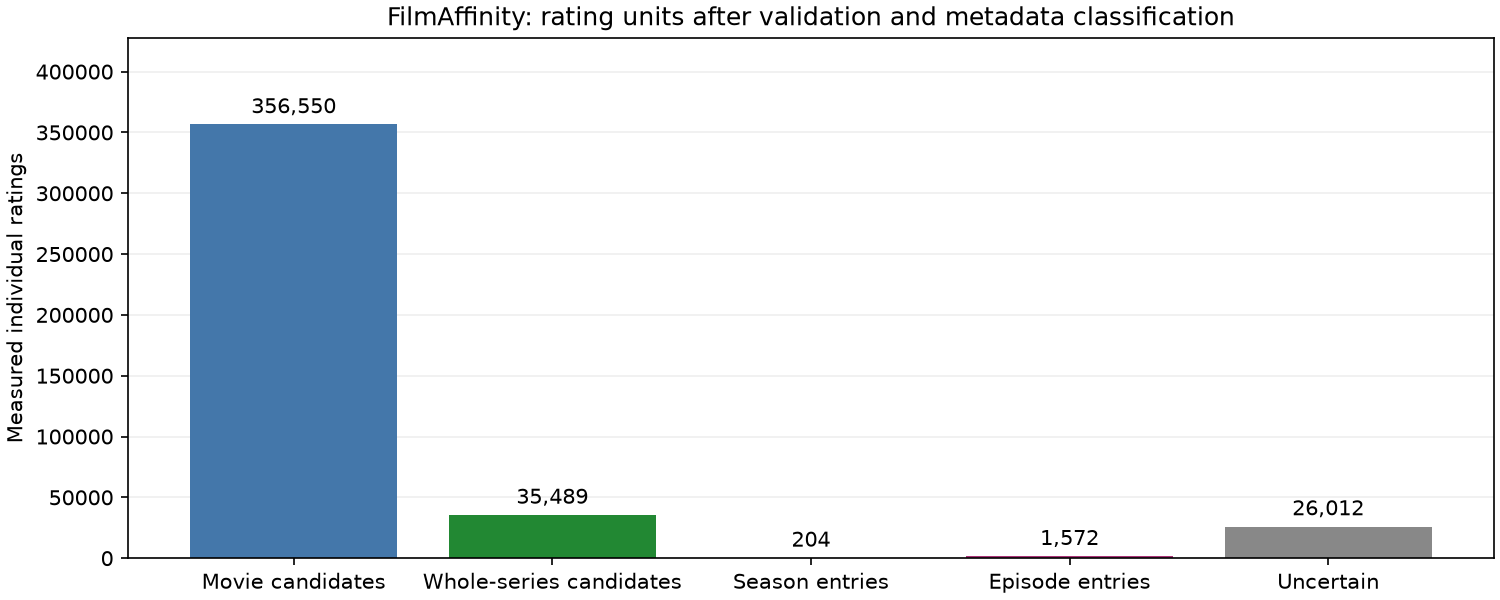

In [8]:
if fa:
    units = result["exports"]["filmaffinity_unit_counts.csv"].groupby("unit")["ratings"].sum()
    ordered_units = ["movie", "whole_series", "season", "episode", "uncertain"]
    values = units.reindex(ordered_units, fill_value=0)
    fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
    bars = ax.bar(["Movie candidates", "Whole-series candidates", "Season entries", "Episode entries", "Uncertain"],
                  values, color=["#4477AA", "#228833", "#EE9933", "#AA3377", "#888888"])
    ax.bar_label(bars, labels=[f"{int(value):,}" for value in values], padding=3)
    ax.set(ylabel="Measured individual ratings", title="FilmAffinity: rating units after validation and metadata classification")
    ax.set_ylim(0, float(values.max()) * 1.2)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    chart = result["output"] / "filmaffinity_rating_units.png"
    fig.savefig(chart, dpi=150)
    plt.close(fig)
    display(Image(filename=str(chart)))
    result["report"]["files"][chart.name] = {"sha256": sha256_file(chart)}


## Access and usage evidence

- **FilmAffinity:** the pinned curator card declares MIT. That is the uploader's declaration, not an independent legal certification of all upstream FilmAffinity content. Review the intended use before incorporating raw or derived data into the shared app.
- **MyAnimeList:** the retrieved curator files do not establish a dataset license. A code license or a third-party dataset label is not automatically a license for this release. Resolve this before adoption.
- **Douban:** the dataset documentation permits research with attribution, restricts commercial use and redistribution without permission, and is separate from the repository's MIT code license.
- An inaccessible sample or gated archive remains **not measured**. No one is required to provide credentials, contact an author, follow social accounts or bypass access controls to run the cached audit.


In [9]:
audit_choice = result.get("decision", {})
recommended_name = audit_choice.get("recommended_dataset") or "Not established"
display(Markdown("## Recommended next data source: **" + str(recommended_name) + "**"))
print(audit_choice.get("decision_status", ""))
print(audit_choice.get("reason", ""))
display(result["summary"][["dataset", "rating_scale", "time_field", "external_ids", "license_evidence", "recommendation"]])
for index, task in enumerate(audit_choice.get("remaining_work", []), 1):
    print(f"{index}. {task}")

report_path = result["output"] / "audit_report.json"
_ = report_path.write_text(
    json.dumps(result["report"], indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")
print("Final report:", report_path)


best verified prototype candidate among retrieved inputs; conditional on manual unit/link/rights review
Actual individual ratings join to whole-series candidates and movie candidates from the same users; accessible title metadata and review dates support a reproducible prototype audit.
1. Review the exported title-unit examples and ambiguous cases; heuristic confidence is not a correctness guarantee.
2. Build and verify an IMDb/TMDB crosswalk; local exact-title/year matches are proposals only.
3. Review uploader/upstream usage conditions before moving data or derived assets into the shared app.
4. Treat review dates as proxies; establish an honest split/evaluation protocol before any model accuracy claim.
5. Audit reviewer-selection bias and sparse-user coverage before model training.
Final report: C:\Users\clark\OneDrive\Documents\Projects\movie-recommendation-system\data\processed\notebook16_dataset_audit\audit_report.json


## Recommended next data source: **FilmAffinity**

,dataset,rating_scale,time_field,external_ids,license_evidence,recommendation
0,FilmAffinity,1--10 integer; only valid explicit scores retained,review publication date; rating-event timing unverified,FilmAffinity IDs; no published IMDb/TMDB crosswalk in these schemas,Uploader-declared MIT in pinned card; upstream rights not independently certified,Primary candidate if whole-series/shared-user coverage is nonzero; metadata class...
1,MyAnimeList 2020,1--10 integer; zero is unscored in list data,No rating-event date in published sample schema,MAL anime IDs; IMDb/TMDB crosswalk not part of the sampled release,No dataset license found in fetched curator files; requires clarification,Secondary anime benchmark; not a direct broad-TV whole-series dataset
2,Douban MovieData-10M,Curator documents integer 1--5; rows not measured,Curator documents RATING_TIME; values not measured,Curator documents IMDB_ID; coverage not measured,"Dataset docs: research only, attribution, no redistribution without permission; c...",Unranked pending accessible data and whole-series unit verification


## What comes after this audit?

If FilmAffinity passes the remaining unit/link/usage review, build a **separate movie-and-whole-series experiment** from its consistently identified users. Reuse the recommendation approach while fitting its collaborative basis and content features on that dataset's training data. Do not attach FilmAffinity users to MovieLens user IDs.

Use shared movie/TV profiles to test a joint recommender, plus content fallback for titles without collaborative evidence. Report label scope, sparse histories and the review-date proxy honestly. Any future accuracy comparison with an LLM must use the same users, feedback access and candidate rules.

The historical MovieLens Recall@10 is not directly comparable with scores from another dataset. This notebook chooses a data source; it makes no new model-quality claim.

Reproduce from the repository root:

```powershell
.\.venv\Scripts\python.exe -m pip install -r requirements-audit.txt
.\.venv\Scripts\python.exe scripts/prepare_ratings_dataset_audit.py
.\.venv\Scripts\python.exe scripts/ratings_dataset_audit.py
.\.venv\Scripts\python.exe -m unittest discover -s tests -p test_notebook16.py -v
```

After preparation, `prepare_ratings_dataset_audit.py --offline` verifies cached inputs without network requests.
CSV results, cleaned source-specific ratings, unit examples, proposed local title links, source receipts and the report are saved under
`data/processed/notebook16_dataset_audit/`. Raw snapshots remain in
`data/raw/notebook16_dataset_audit/`.
